# Figures

Load simulation data

In [1]:
include("packages.jl")

filename = "PigA_bg50_u_35_putida2026-03-23_11-25.jld2"

@load filename sol local_tags_list

🔧 Julia started with 12 threads


2-element Vector{Symbol}:
 :sol
 :local_tags_list

## Data preparation

In [2]:
df_list = sequence_dataframes(sol, local_tags_list); # Divide sequences in a list of dataframes that have the metabolites for all and the ribosomes for one sequence
sequences = Dict(x => i for (i, x) in enumerate(local_tags_list[1].seq_names)) # Dictionary that connects the index with the name of a sequence in local_tags_list
println("Sequences in data set:")
for i in eachindex(local_tags_list[1].seq_names)
    println(local_tags_list[1].seq_names[i])
end

Sequences in data set:
pigA
lpp
rplE
rplU
rpmJ
tufA
fusA
ompF
tufB
acpP
rpsK
gapA
rpsL
rpsM
rplX
rplO
cspC
ompT
rpsS
ompA
rplN
rplK
rpoA
rplM
rpsJ
rpsH
icdA
rplV
rpmB
rplJ
b1824
rplW
rpsD
gatZ
infC
prlA
pyrB
rplA
rplF
rpsG
rplD
yceD
rpsA
rplC
nlpD
rpmG
gatY
gatA
rpsC
cysK
rplY


## Translation elongation rate profile

In [10]:
default(
	linewidth 	= 3,
	guidefont 	= font(26),
	tickfont 	= font(18),
	legendfont	= font(18)
	)

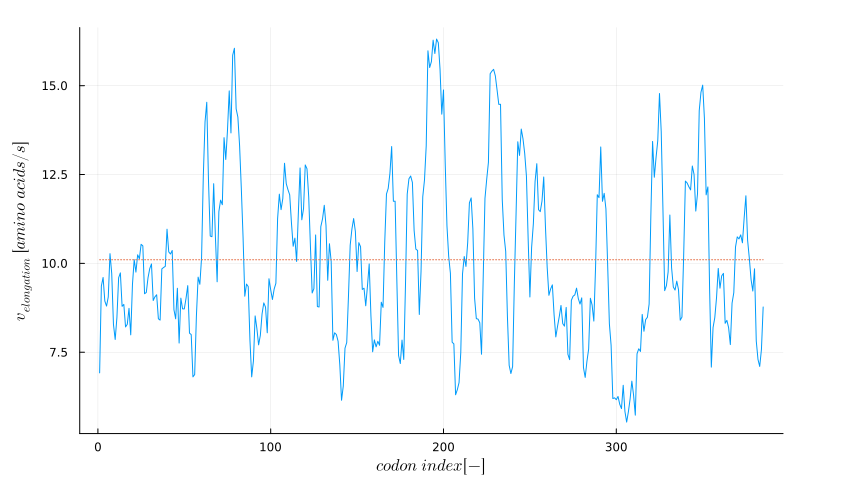

In [3]:
# Function input
sequence_name    = "pigA"
idx         = sequences[sequence_name]
tags        = local_tags_list[idx]
y           = df_list[idx][end,2:end] |> collect;
c_RIB       = y[tags.idx_first_codon:end];

# Calculation
V_TL_EL         = calculate_V_TL_EL(tags, y);
V_EL_smooth, h1 = V_TL_EL_smooth(tags, V_TL_EL, c_RIB)

# Plotting
plot(V_EL_smooth, xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, label = false)
plot!(h1, linestyle =:dot, label = false)

## Time courses of state variables

In [4]:
sequence_name    = "pigA"
idx         = sequences[sequence_name]

variable  = :PRT

t           = df_list[idx].time
metabolite  = df_list[idx][!,variable];

In [5]:
default(
	linewidth 	= 3,
	guidefont 	= font(18),
	tickfont 	= font(18),
	legendfont	= font(8)
	)

In [6]:
println("="^60)
println("PRT summary for: $sequence_name")
println("="^60)
println("  Final PRT (t=$(t[end]) min):  $(metabolite[end]) µM")
if length(t) >= 2
    dPRT_dt = (metabolite[end] - metabolite[end-1]) / (t[end] - t[end-1])
    println("  dPRT/dt at end:              $dPRT_dt µM/min")
    println("  (= $(dPRT_dt/60) µM/s)")
end
println("="^60)

PRT summary for: pigA
  Final PRT (t=100.0 min):  0.042400434210319984 µM
  dPRT/dt at end:              0.00042741078707268787 µM/min
  (= 7.1235131178781314e-6 µM/s)


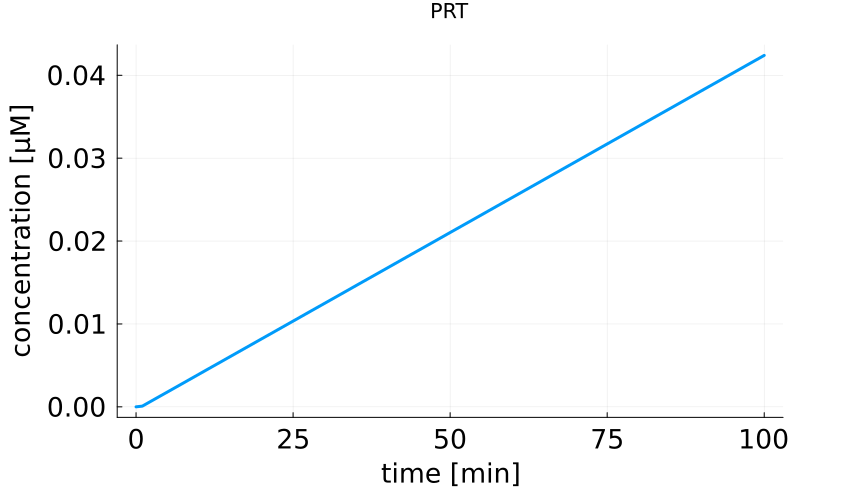

In [7]:
# Plotting
plot(t, metabolite, xlabel = "time [min]", 
	ylabel = "concentration [µM]", title = String(variable),
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, label = false)

#### Save figure

In [ ]:
foldername 	= joinpath(pwd(),"output" ,"plots") 
filename 	= String(variable)
filepath = joinpath(foldername, filename)
savefig(filepath)

"c:\\Users\\cedri\\TXTLv2\\src\\output\\plots"

## Translation rate

In [9]:
translation_rate = calculate_translation_rate(df_list[idx])

UndefVarError: UndefVarError: `calculate_translation_rate` not defined

## Overview over pool metabolites

In [8]:
example = df_list[end]
pool = example[end, 1:137]
for i in pool
    println(i)
end

100.0
19.521213007044157
19.462410582712973
0.011807189333278588
0.02099682134415266
2.42023853736277
1.5223310620645605
0.6548297198162676
0.7374689580911624
0.20824981079027607
2.3266091135260205
0.0946855160768704
24.505760436692395
15.79278985084743
23.680055474132217
33.40947244302521
1.208340506310991e-6
0.40304430018454696
0.24344511763653842
3.353036534107293
0.021208337228428336
0.001985837802265324
0.0016375916812478612
0.0036413777512128917
0.0009436807435047916
0.009272959748253639
0.00024724428436174794
0.005274832276872736
0.0006959696488329399
0.009729410988009722
0.014178125637416097
0.008300765170736928
0.0013972605927115704
0.0014476973302935186
0.0002604965652897223
0.0005098233942164502
0.015328819772431309
0.0005727939178842971
0.005065771845584905
0.0013897009073771025
0.005849077717434791
0.00021210866859090258
0.0009020826208676688
0.03818165366837951
0.0003815305170348957
0.0010487640008868117
1.122686555723555e-20
0.0007229013422721956
8.968025342284828e-6
0.0

## Analysis of E.coli gene set

In [5]:
include("packages.jl")

# Load data
mRNA_copy_numbers	= to_DataFrame(readmatrix("../data/input/mRNA_copy_numbers.xlsx", "mRNA_copy_number", "A1:E2472"))
first(mRNA_copy_numbers,3)

🔧 Julia started with 8 threads


Row,Gene,Locus_tag,Length,GeneID,mRNA_molecules_per_cell
,Any,Any,Any,Any,Any
1,lpp,b1677,78,946175,63.6042
2,rplE,b3308,179,947800,57.9722
3,rplU,b3186,103,949057,57.4624


In [6]:
size(mRNA_copy_numbers,1)
# Initialization of arrays 
number_of_genes = zeros(size(mRNA_copy_numbers,1))
number_of_mRNA  = zeros(size(mRNA_copy_numbers,1))
mRNA_molecules  = 0

for (idx, gene) in enumerate(mRNA_copy_numbers.mRNA_molecules_per_cell)
    mRNA_molecules += gene
    number_of_genes[idx] = idx
    number_of_mRNA[idx]  = mRNA_molecules
end


In [15]:
# 1. Schwellenwert berechnen (90% vom Maximum)
threshold = 0.90 * maximum(number_of_mRNA)

# 2. Den ersten Index finden, an dem y diesen Wert erreicht oder überschreitet
idx = findfirst(val -> val >= threshold, number_of_mRNA)

# 3. Den entsprechenden x-Wert abrufen
x_value = number_of_genes[idx]

println("Der Index ist: $idx")
println("Der x-Wert bei 90% ist: $x_value")

Der Index ist: 1269
Der x-Wert bei 90% ist: 1269.0


In [12]:
maximum(number_of_mRNA)*0.9

9242.156150153856

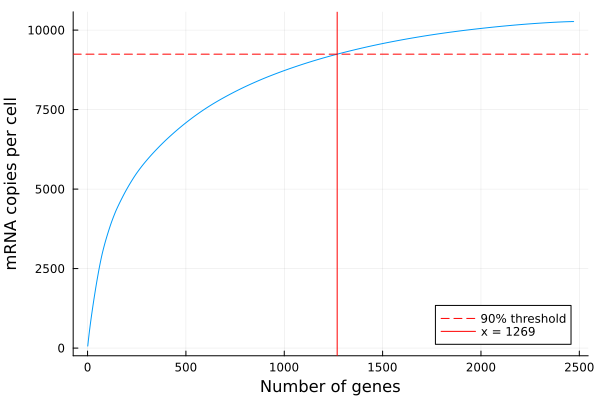

In [34]:
plot(number_of_genes, number_of_mRNA,
xlabel = "Number of genes",
ylabel = "mRNA copies per cell",
label  = false)

# 2. Horizontale Linie bei 90% des Max-Werts einfügen
hline!([threshold], color=:red, linestyle=:dash, label="90% threshold")

# 3. Vertikale Linie beim entsprechenden X-Wert einfügen
vline!([x_value], color=:red, label="x = $(Int(x_value))")

In [24]:
mean_length = mean(skipmissing(mRNA_copy_numbers.Length))
codons = Int(round(mean_length))*Int(x_value)

413694

In [38]:
mean_length

325.6269879518072

In [37]:
number_of_genes[end]*mean_length

804624.2872289156

In [25]:
println("Number of codons necessary for 90% solution: ", codons)

Number of codons necessary for 90% solution: 413694


In [8]:
sum(skipmissing(mRNA_copy_numbers.Length))+130

675806